# Building Heating and Cooling Load Prediction

This notebook predicts heating load (Heating_Load) and cooling load (Cooling_Load) from eight building design features using the UCI Energy Efficiency dataset.

## Step 1: Imports and load data

Import the existing data and modeling tools, and fix the random seed so the train/test split and randomized search are reproducible.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
FEATURES = ["Relative_Compactness", "Surface_Area", "Wall_Area", "Roof_Area", "Overall_Height", "Orientation", "Glazing_Area", "Glazing_Area_Distribution"]
TARGETS = ["Heating_Load", "Cooling_Load"]

Load the UCI data (or its local copy), standardize column labels, rename them once, and keep only the eight inputs and two targets used below.

In [2]:
# Load the UCI dataset; use the local CSV when the UCI service or network is unavailable.
try:
    from ucimlrepo import fetch_ucirepo
    data = fetch_ucirepo(id=242)
    df = pd.concat([data.data.features, data.data.targets], axis=1)
except Exception:
    df = pd.read_csv("ENB2012_data.csv")

# Remove only wholly empty rows/columns; preserve any partially populated observations.
df = df.dropna(how="all").dropna(axis=1, how="all")
df.columns = [c.strip().upper() for c in df.columns]
rename_map = dict(zip(df.columns, ["Relative_Compactness", "Surface_Area", "Wall_Area", "Roof_Area",
                                  "Overall_Height", "Orientation", "Glazing_Area",
                                  "Glazing_Area_Distribution", "Heating_Load", "Cooling_Load"]))
df = df.rename(columns=rename_map)
FEATURES = ["Relative_Compactness", "Surface_Area", "Wall_Area", "Roof_Area", "Overall_Height",
            "Orientation", "Glazing_Area", "Glazing_Area_Distribution"]
TARGETS = ["Heating_Load", "Cooling_Load"]
df = df[FEATURES + TARGETS]
print(df.shape)
df.head()

(768, 10)


,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


The loaded dataset contains **768 rows and 10 columns**. The first records now display the descriptive feature and target names.

## Step 2: Inspect and check data quality

Check completeness, duplicates, basic statistics, and the building-area identity to confirm the data are usable and reveal structural redundancy.

In [3]:
df.info()
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Is Surface_Area == Wall_Area + 2*Roof_Area ?", np.allclose(df["Surface_Area"], df["Wall_Area"] + 2 * df["Roof_Area"]))
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Relative_Compactness       768 non-null    float64
 1   Surface_Area               768 non-null    float64
 2   Wall_Area                  768 non-null    float64
 3   Roof_Area                  768 non-null    float64
 4   Overall_Height             768 non-null    float64
 5   Orientation                768 non-null    int64  
 6   Glazing_Area               768 non-null    float64
 7   Glazing_Area_Distribution  768 non-null    int64  
 8   Heating_Load               768 non-null    float64
 9   Cooling_Load               768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB
Missing values:
 Relative_Compactness         0
Surface_Area                 0
Wall_Area                    0
Roof_Area                    0
Overall_Height               0
Orientation

,count,mean,std,min,25%,50%,75%,max
Relative_Compactness,768.0,0.764167,0.105777,0.62,0.6825,0.75,0.8300,0.98
Surface_Area,768.0,671.708333,88.086116,514.50,606.3750,673.75,741.1250,808.50
Wall_Area,768.0,318.500000,43.626481,245.00,294.0000,318.50,343.0000,416.50
Roof_Area,768.0,176.604167,45.165950,110.25,140.8750,183.75,220.5000,220.50
Overall_Height,768.0,5.250000,1.751140,3.50,3.5000,5.25,7.0000,7.00
Orientation,768.0,3.500000,1.118763,2.00,2.7500,3.50,4.2500,5.00
Glazing_Area,768.0,0.234375,0.133221,0.00,0.1000,0.25,0.4000,0.40
Glazing_Area_Distribution,768.0,2.812500,1.550960,0.00,1.7500,3.00,4.0000,5.00
Heating_Load,768.0,22.307201,10.090196,6.01,12.9925,18.95,31.6675,43.10
Cooling_Load,768.0,24.587760,9.513306,10.90,15.6200,22.08,33.1325,48.03


All **768 rows** are populated in each of the 10 columns, with **0 missing values** and **0 duplicate rows**. The geometric identity `Surface_Area = Wall_Area + 2 × Roof_Area` is **True for every row**.

## Step 3: Exploratory data analysis

Plot every variable distribution to see the range, shape, and discrete design choices before modeling.

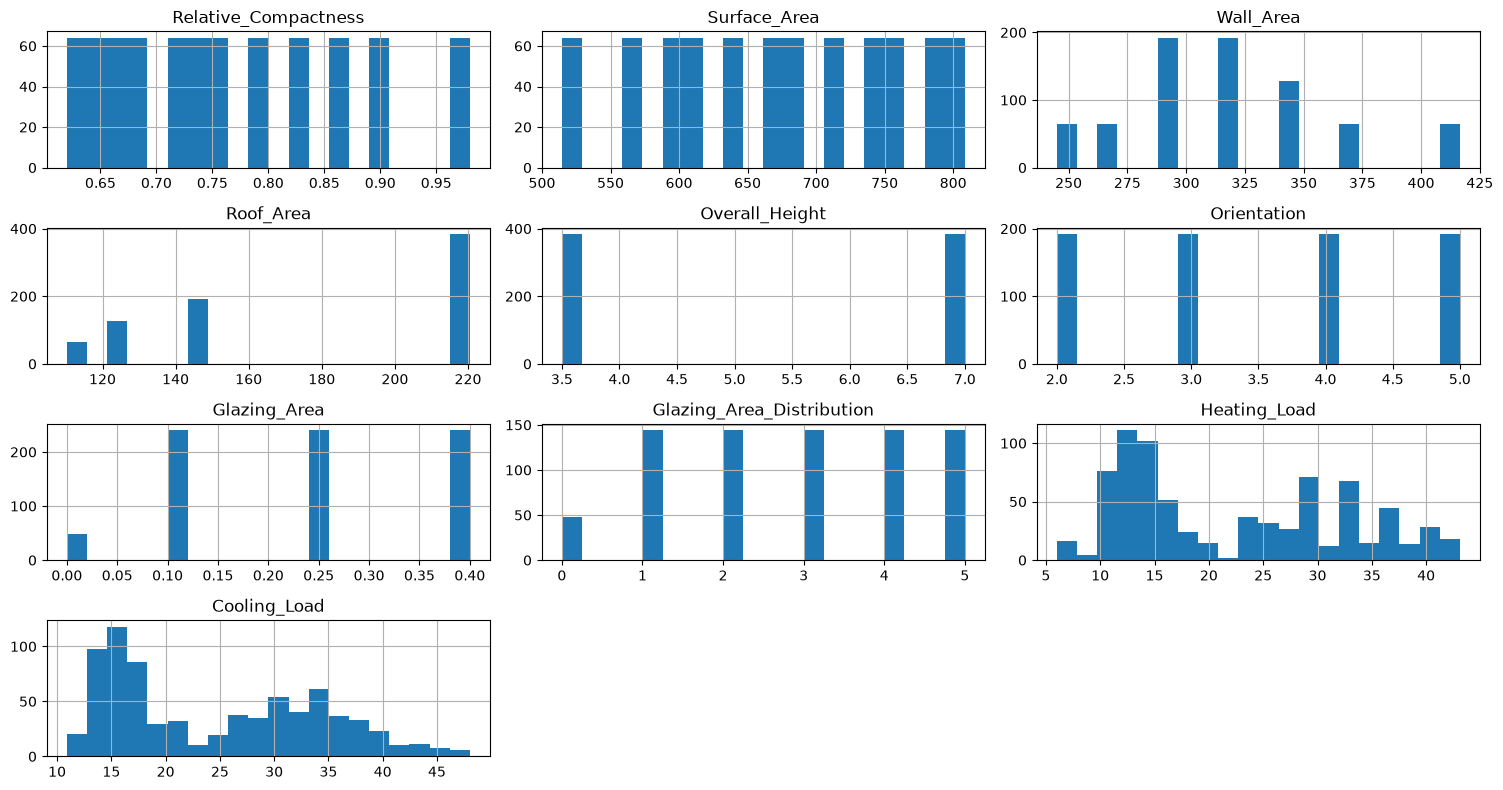

In [4]:
df.hist(bins=20, figsize=(15, 8))
plt.tight_layout()
plt.show()

The histograms show repeated design settings across the inputs and broad target ranges: **Heating_Load 6.01–43.10** and **Cooling_Load 10.90–48.03**.

Compare each variable’s spread and potential outliers on a common set of box plots.

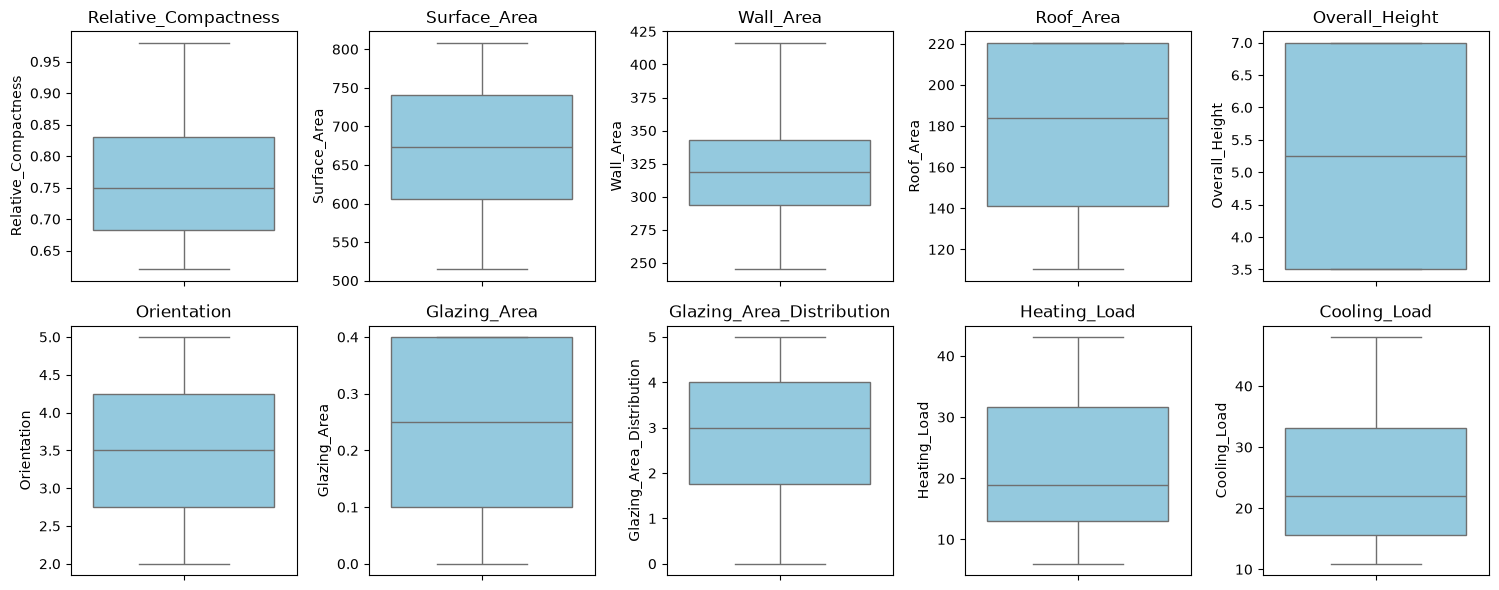

In [5]:
plt.figure(figsize=(15, 6))
for i, col in enumerate(df.columns, 1):
    plt.subplot(2, 5, i)
    sns.boxplot(y=df[col], color="skyblue")
    plt.title(col)
plt.tight_layout()
plt.show()

The box plots make the different ranges and spreads visible across the eight design inputs and two load targets; the cells retain all observations.

Measure pairwise linear correlations and focus on how each design input relates to the two energy-load targets.

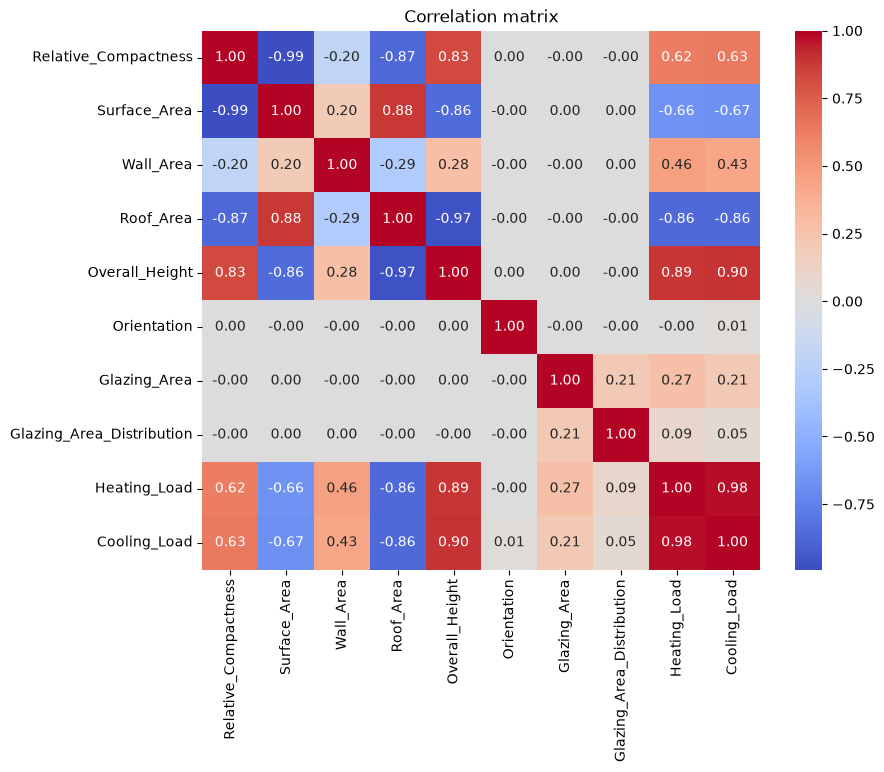

                           Heating_Load  Cooling_Load
Relative_Compactness              0.622         0.634
Surface_Area                     -0.658        -0.673
Wall_Area                         0.456         0.427
Roof_Area                        -0.862        -0.863
Overall_Height                    0.889         0.896
Orientation                      -0.003         0.014
Glazing_Area                      0.270         0.208
Glazing_Area_Distribution         0.087         0.051
Correlation between Heating_Load and Cooling_Load: 0.976


In [6]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

print(df.corr().loc[FEATURES, TARGETS].round(3))
print("Correlation between Heating_Load and Cooling_Load:", round(df["Heating_Load"].corr(df["Cooling_Load"]), 3))

The strongest target correlations are `Overall_Height` (**0.889** heating, **0.896** cooling) and `Roof_Area` (**−0.862**, **−0.863**). `Surface_Area` is also negatively correlated (**−0.658**, **−0.673**); `Orientation` is near zero (**−0.003**, **0.014**). Heating and cooling loads correlate **0.976**.

Plot each input against both targets to reveal trends or patterns that a correlation number alone may hide.

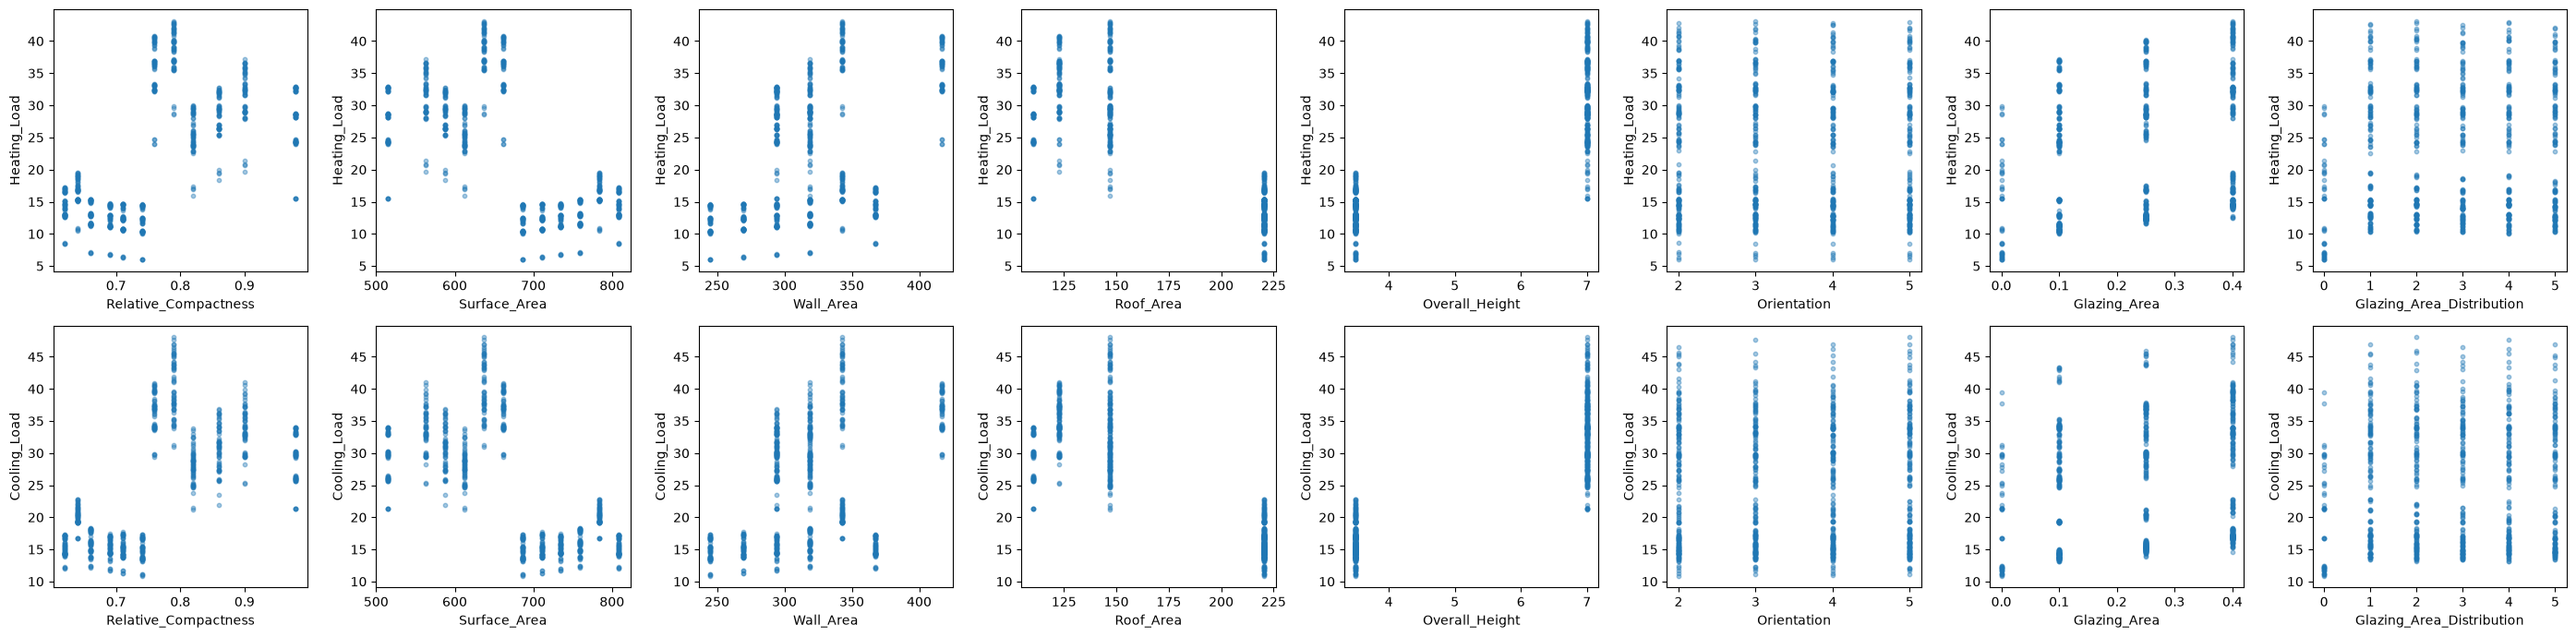

In [7]:
fig, axes = plt.subplots(2, 8, figsize=(28, 7))
for r, t in enumerate(TARGETS):
    for c, f in enumerate(FEATURES):
        axes[r, c].scatter(df[f], df[t], alpha=0.4, s=10)
        axes[r, c].set_xlabel(f)
        axes[r, c].set_ylabel(t)
plt.tight_layout()
plt.show()

The scatter plots show loads rising with `Overall_Height` and generally falling with `Roof_Area`/`Surface_Area`; `Orientation` and glazing distribution show weak trends. Repeated settings create visible bands, with some non-linear structure.

## EDA findings

- The 768 rows have no missing values or duplicate rows. Design inputs occupy repeated settings; Heating_Load ranges from **6.01 to 43.10**, and Cooling_Load from **10.90 to 48.03**.
- `Overall_Height` has the strongest positive correlation with heating and cooling (**0.889**, **0.896**); `Roof_Area` has the strongest negative correlation (**−0.862**, **−0.863**). `Surface_Area` correlations are **−0.658** and **−0.673**. `Orientation` is nearly uncorrelated (**−0.003**, **0.014**), while `Glazing_Area_Distribution` is weakly correlated (**0.087**, **0.051**). The targets correlate **0.976** with each other.
- `Surface_Area = Wall_Area + 2 × Roof_Area` is true for all rows, so these geometric inputs are redundant rather than independent.
- Scatter plots echo the correlations: loads generally rise with `Overall_Height`, fall with roof/surface area, and have weaker relationships with orientation and glazing distribution. Repeated design settings form bands, with some non-linear patterns.

## Step 4: Features, targets, split, and scaling

Separate a fixed 20% holdout set and standardize inputs using training data only, preventing test-set leakage.

In [8]:
X = df[FEATURES]
Y = df[TARGETS]

# Keep the holdout independent and reproducible.
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=SEED)

scaler = StandardScaler()
# Fit scaling only on training inputs to avoid leaking test-set statistics.
X_train_s = scaler.fit_transform(X_train)
# Apply the training-set scale unchanged to the holdout inputs.
X_test_s = scaler.transform(X_test)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (614, 8)  Test: (154, 8)


The reproducible split contains **614 training rows** and **154 test rows**, each with **8 features**.

## Step 5: Train baseline models

Fit the four existing baseline regressors for each target and compare holdout error with five-fold training cross-validation.

In [9]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=SEED),
    "XGBoost": XGBRegressor(n_estimators=100, random_state=SEED),
    "SVR": SVR(kernel="rbf", C=100),
}

def get_scores(model, name, target):
    pred = model.predict(X_test_s)
    mse = mean_squared_error(Y_test[target], pred)
    # Negate sklearn’s negative-loss score to report RMSE in its usual positive units.
    cv_rmse = -cross_val_score(model, X_train_s, Y_train[target], cv=5,
                               scoring="neg_root_mean_squared_error").mean()
    return {"Model": name, "Target": target,
            "MAE": mean_absolute_error(Y_test[target], pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "R2": r2_score(Y_test[target], pred),
            "CV_RMSE": cv_rmse}

fitted = {}
results = []
for target in TARGETS:
    for name, model in models.items():
        # Clone so each target/model pair gets an independent fitted estimator.
        m = clone(model).fit(X_train_s, Y_train[target])
        fitted[(name, target)] = m
        results.append(get_scores(m, name, target))

pd.DataFrame(results).round(4)

,Model,Target,MAE,MSE,RMSE,R2,CV_RMSE
0,Linear Regression,Heating_Load,2.1820,9.1532,3.0254,0.9122,2.9292
1,Random Forest,Heating_Load,0.3540,0.2435,0.4934,0.9977,0.5153
2,XGBoost,Heating_Load,0.2636,0.1659,0.4074,0.9984,0.4005
3,SVR,Heating_Load,0.5614,0.5398,0.7347,0.9948,1.1637
4,Linear Regression,Cooling_Load,2.1953,9.8934,3.1454,0.8932,3.2292
5,Random Forest,Cooling_Load,1.0720,2.9612,1.7208,0.9680,1.6888
6,XGBoost,Cooling_Load,0.4486,0.7367,0.8583,0.9920,1.0879
7,SVR,Cooling_Load,1.1369,3.1917,1.7865,0.9656,1.9475


Among the baseline models, **XGBoost** has the lowest holdout RMSE for both targets: **0.4074** (R² **0.9984**) for heating and **0.8583** (R² **0.9920**) for cooling.

## Step 6: Hyperparameter tuning

Search the existing Random Forest, XGBoost, and SVR parameter spaces with randomized three-fold CV, then score each selected estimator.

In [10]:
param_grids = {
    "Random Forest": (RandomForestRegressor(random_state=SEED),
                      {"n_estimators": [50, 100, 200, 300], "max_depth": [None, 10, 20, 30],
                       "min_samples_split": [2, 5, 10], "min_samples_leaf": [1, 2, 4]}),
    "XGBoost": (XGBRegressor(random_state=SEED),
                {"n_estimators": [100, 200, 300], "max_depth": [2, 3, 4, 6],
                 "learning_rate": [0.03, 0.05, 0.1, 0.2], "subsample": [0.7, 0.85, 1.0]}),
    "SVR": (SVR(kernel="rbf"),
            {"C": [1, 10, 100, 1000], "gamma": ["scale", 0.01, 0.1, 1], "epsilon": [0.01, 0.1, 0.5]}),
}

for target in TARGETS:
    for name, (model, grid) in param_grids.items():
        # Randomly sample ten settings with three-fold CV; SEED makes the search repeatable.
        search = RandomizedSearchCV(model, grid, n_iter=10, cv=3, random_state=SEED,
                                    scoring="neg_root_mean_squared_error")
        search.fit(X_train_s, Y_train[target])
        tuned_name = name + " (tuned)"
        fitted[(tuned_name, target)] = search.best_estimator_
        results.append(get_scores(search.best_estimator_, tuned_name, target))
        print(name, target, search.best_params_)

Random Forest Heating_Load {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': None}


XGBoost Heating_Load {'subsample': 0.85, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.1}


SVR Heating_Load {'gamma': 'scale', 'epsilon': 0.1, 'C': 1000}


Random Forest Cooling_Load {'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': 30}


XGBoost Cooling_Load {'subsample': 0.7, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.2}


SVR Cooling_Load {'gamma': 'scale', 'epsilon': 0.1, 'C': 1000}


The randomized searches report one selected parameter set for each of the three tuned model families and each target. Their holdout impact is compared in the next table.

## Step 7: Compare and evaluate

Save and sort all baseline and tuned scores by target and holdout RMSE for direct model comparison.

In [11]:
results_df = pd.DataFrame(results).round(4)
results_df.to_csv("model_comparison.csv", index=False)
results_df.sort_values(["Target", "RMSE"])

,Model,Target,MAE,MSE,RMSE,R2,CV_RMSE
6,XGBoost,Cooling_Load,0.4486,0.7367,0.8583,0.9920,1.0879
12,XGBoost (tuned),Cooling_Load,0.5653,0.9660,0.9828,0.9896,0.8872
13,SVR (tuned),Cooling_Load,0.8542,2.1508,1.4665,0.9768,1.5390
5,Random Forest,Cooling_Load,1.0720,2.9612,1.7208,0.9680,1.6888
7,SVR,Cooling_Load,1.1369,3.1917,1.7865,0.9656,1.9475
11,Random Forest (tuned),Cooling_Load,1.2283,3.6408,1.9081,0.9607,1.7700
4,Linear Regression,Cooling_Load,2.1953,9.8934,3.1454,0.8932,3.2292
9,XGBoost (tuned),Heating_Load,0.2780,0.1507,0.3882,0.9986,0.3688
2,XGBoost,Heating_Load,0.2636,0.1659,0.4074,0.9984,0.4005
10,SVR (tuned),Heating_Load,0.3451,0.2096,0.4578,0.9980,0.6248


The lowest holdout RMSE is **0.3882** for tuned XGBoost on heating (R² **0.9986**) and **0.8583** for baseline XGBoost on cooling (R² **0.9920**). Tuning improves heating RMSE from **0.4074** to **0.3882**, but tuned XGBoost worsens cooling RMSE from **0.8583** to **0.9828**.

Visualize holdout RMSE and R² for each model so accuracy trade-offs are easy to compare by target.

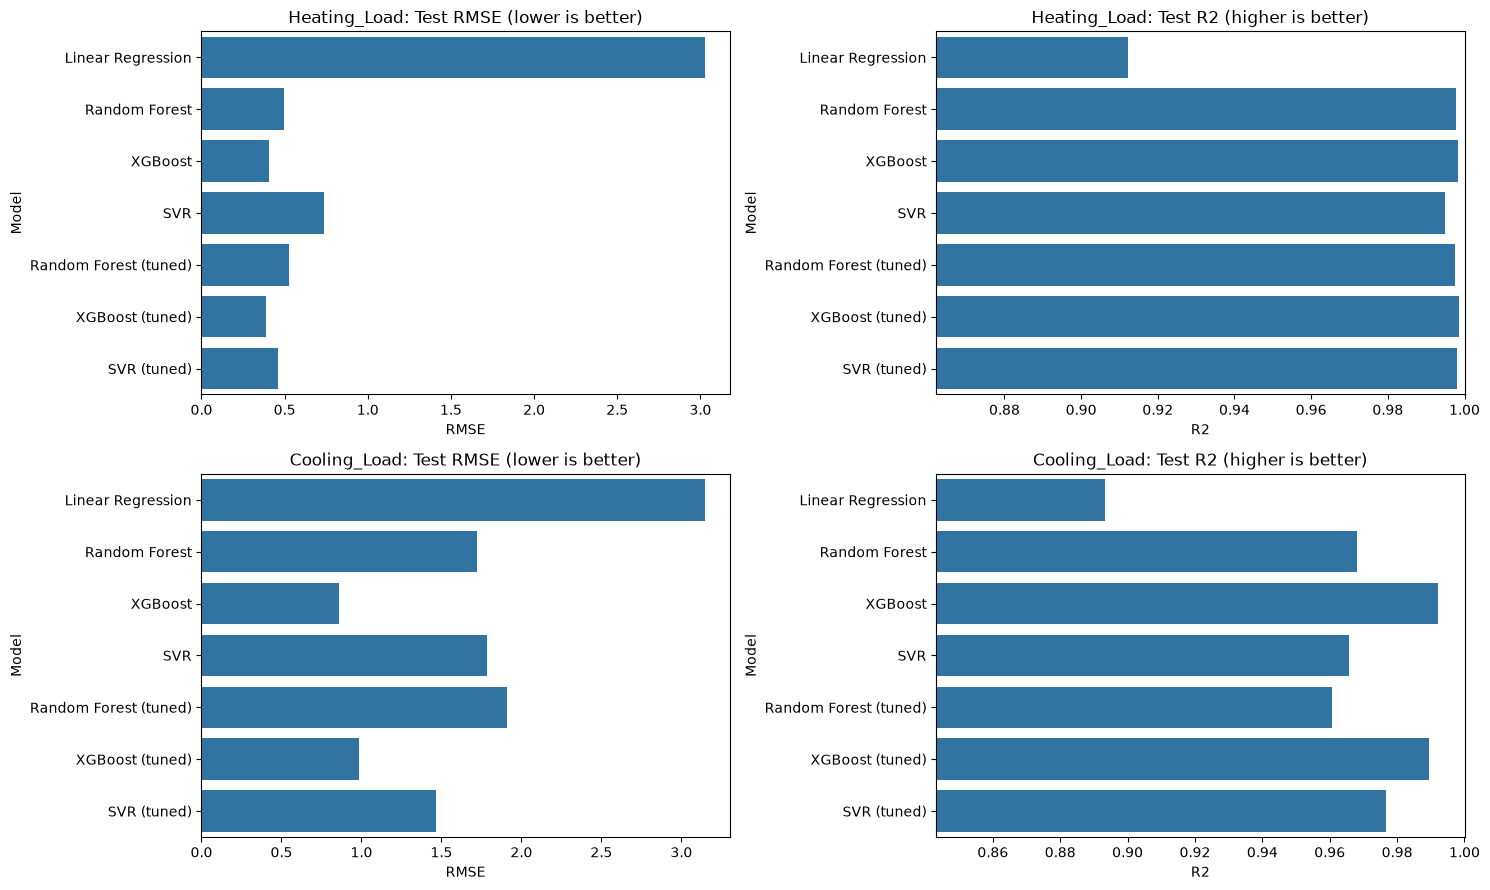

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for i, t in enumerate(TARGETS):
    sub = results_df[results_df["Target"] == t]
    sns.barplot(data=sub, y="Model", x="RMSE", ax=axes[i, 0])
    axes[i, 0].set_title(f"{t}: Test RMSE (lower is better)")
    sns.barplot(data=sub, y="Model", x="R2", ax=axes[i, 1])
    axes[i, 1].set_xlim(max(0, sub["R2"].min() - 0.05), 1)
    axes[i, 1].set_title(f"{t}: Test R2 (higher is better)")
plt.tight_layout()
plt.show()

The bars confirm that tuned XGBoost leads the heating comparison, while baseline XGBoost leads cooling on the holdout set; scores remain high for both targets.

Fit the four existing baseline regressors for each target and compare holdout error with five-fold training cross-validation.

Best model for Heating_Load: XGBoost (tuned)
Best model for Cooling_Load: XGBoost (tuned)


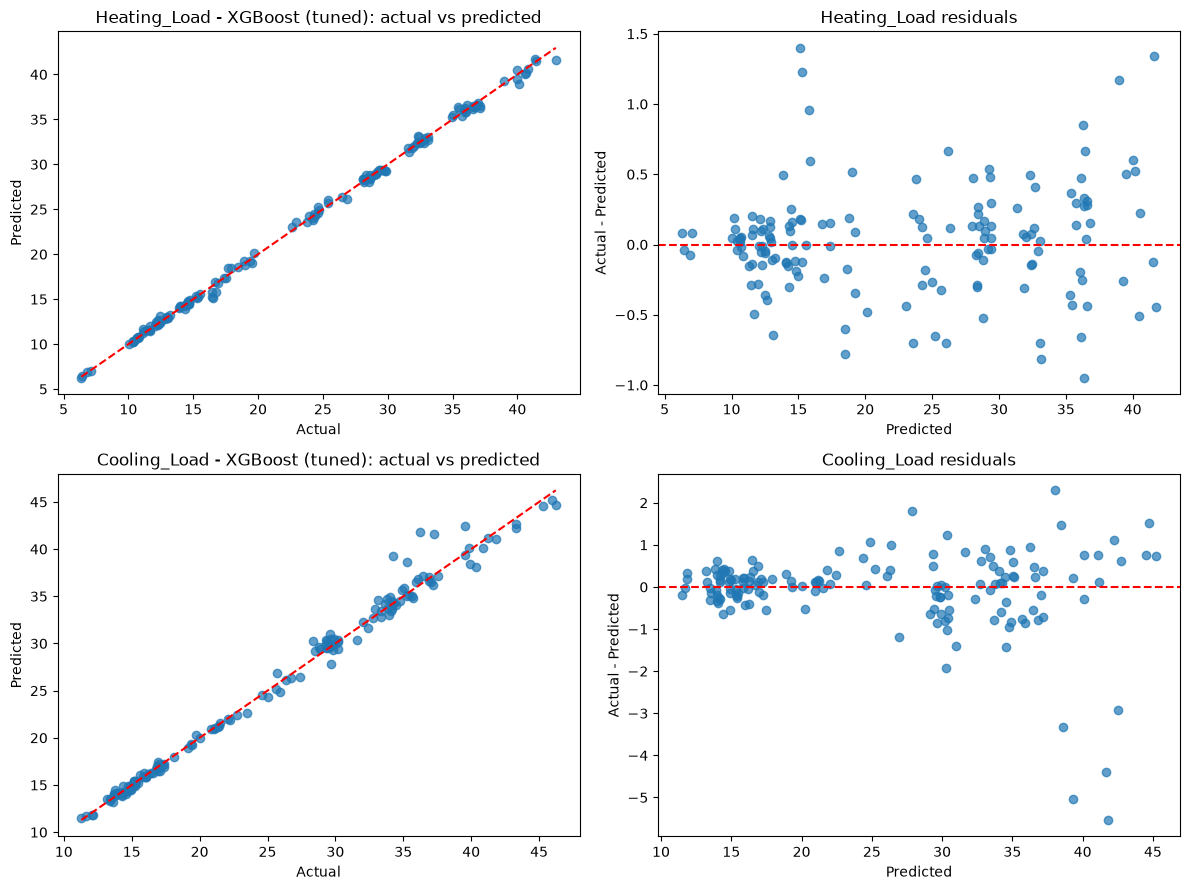

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
best_models = {}
for i, t in enumerate(TARGETS):
    sub = results_df[results_df["Target"] == t]
    best_name = sub.loc[sub["CV_RMSE"].idxmin(), "Model"]
    best_models[t] = fitted[(best_name, t)]
    pred = best_models[t].predict(X_test_s)
    actual = Y_test[t]

    axes[i, 0].scatter(actual, pred, alpha=0.7)
    axes[i, 0].plot([actual.min(), actual.max()], [actual.min(), actual.max()], "r--")
    axes[i, 0].set(title=f"{t} - {best_name}: actual vs predicted", xlabel="Actual", ylabel="Predicted")

    axes[i, 1].scatter(pred, actual - pred, alpha=0.7)
    axes[i, 1].axhline(0, color="r", linestyle="--")
    axes[i, 1].set(title=f"{t} residuals", xlabel="Predicted", ylabel="Actual - Predicted")
    print(f"Best model for {t}: {best_name}")
plt.tight_layout()
plt.show()

Among the baseline models, **XGBoost** has the lowest holdout RMSE for both targets: **0.4074** (R² **0.9984**) for heating and **0.8583** (R² **0.9920**) for cooling.

Plot tuned Random Forest feature importances and show each target’s three highest-ranked inputs to summarize model-reported influence.

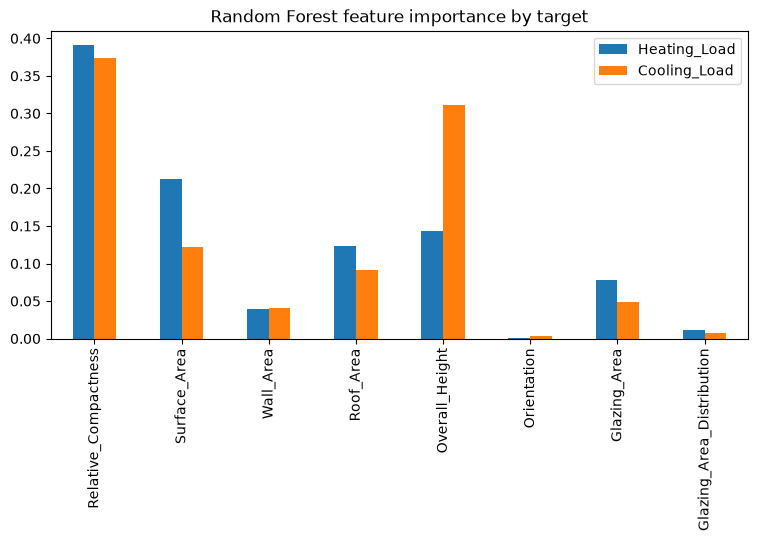

Top three features by target:
Heating_Load {'Relative_Compactness': 0.391, 'Surface_Area': 0.213, 'Overall_Height': 0.143}
Cooling_Load {'Relative_Compactness': 0.374, 'Overall_Height': 0.312, 'Surface_Area': 0.122}


In [14]:
rf_importance = pd.DataFrame({
    "Heating_Load": fitted[("Random Forest (tuned)", "Heating_Load")].feature_importances_,
    "Cooling_Load": fitted[("Random Forest (tuned)", "Cooling_Load")].feature_importances_,
}, index=FEATURES)
rf_importance.plot.bar(figsize=(9, 4), title="Random Forest feature importance by target")
plt.show()
print("Top three features by target:")
for target in rf_importance.columns:
    print(target, rf_importance[target].nlargest(3).round(3).to_dict())

The tuned Random Forest ranks `Relative_Compactness` highest for both targets (**0.391** heating, **0.374** cooling). Next are `Surface_Area` (**0.213**) for heating and `Overall_Height` (**0.312**) for cooling; the printed output lists each target’s top three.

## Step 8: Conclusion

- **Best holdout models:** tuned XGBoost for `Heating_Load` (**RMSE 0.3882, R² 0.9986**) and baseline XGBoost for `Cooling_Load` (**RMSE 0.8583, R² 0.9920**). Five-fold CV instead selects tuned XGBoost for both, illustrating that tuning/CV does not guarantee a better score on this particular holdout.
- **Effect of tuning:** Heating XGBoost improves from RMSE **0.4074** / R² **0.9984** to **0.3882** / **0.9986**. Cooling XGBoost worsens from **0.8583** / **0.9920** to **0.9828** / **0.9896**.
- **Random Forest feature importance:** `Relative_Compactness` is top for both targets (**0.391** heating; **0.374** cooling). `Surface_Area` is next for heating (**0.213**); `Overall_Height` is next for cooling (**0.312**).
- **Limitations:** the dataset is small (**768 rows**) and describes simulated building designs, not measurements from occupied real buildings. The fixed holdout and redundant geometry also limit how broadly these scores and importance rankings should be generalized.